# Ecobici — 05. Bicis de carga en lugar de camión

Alternativa a la redistribución con camión: un operador en una bici adaptada (bici de carga o con remolque) que lleva **a lo más 6 bicis por viaje**. Se usa el mismo modelo de las etapas 2 a 4 y se compara con los resultados del camión.

1. De dónde salen y a dónde van las bicis: cuánto dura cada viaje.
2. El modelo con bicis de carga: un problema de decisión markoviano por estación.
3. Cuántos operadores hacen falta y cómo repartirlos.
4. Simulación Monte Carlo en los escenarios de demanda de `simulacion.ipynb`.
5. Comparación con el camión con los mismos criterios de decisión.

Hay que correr antes `modelo.ipynb`, `camion.ipynb` y `simulacion.ipynb`: de ahí salen las tasas, los lotes, los resultados del camión, los escenarios y la variación entre días.

In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import expm

DIR_TABLAS, DIR_FIG = Path("outputs/tablas"), Path("outputs/figuras")
SUBRED = {"271-272": "Buenavista", "273-274": "Buenavista", "014": "Reforma", "027": "Reforma", "018": "Reforma"}
ORDEN, HORAS = list(SUBRED), np.arange(5, 24)
COLORES = {"Buenavista": "#d1495b", "Reforma": "#2e86ab"}
PASOS = 60                       # pasos de un minuto por hora
MIN_DIA = len(HORAS) * PASOS     # 1,140 minutos de 5:00 a 24:00

# Parámetros de la bici de carga
CAP = 6          # bicis por viaje como máximo
T_CICLO = 30     # minutos por viaje: cargar y descargar 6 bicis (~6 min) + ir cargado y volver entre Reforma y Buenavista (~2.5 km, ~24 min)
W = 0.1          # costo de mover una bici, medido en rechazos (solo para no mover bicis de más)

# Parámetros estimados en modelo.ipynb
tasas = pd.read_csv(DIR_TABLAS / "tasas_modelo.csv", dtype={"estacion": str})
B = pd.read_csv(DIR_TABLAS / "lotes.csv", dtype={"estacion": str}).set_index(["estacion", "proceso"]).b
DOCKS = tasas.groupby("estacion").docks.first().astype(int)

# Resultados del camión (camion.ipynb y simulacion.ipynb), para comparar
cam_pol = pd.read_csv(DIR_TABLAS / "camion_politicas.csv", dtype={"estación": str}).set_index(["política", "estación"])
cam_cap = {"actual": cam_pol.loc["actual"].rechazos.sum(), "propuesta": cam_pol.loc["propuesta"].rechazos.sum()}
cam_sim = pd.read_csv(DIR_TABLAS / "sim_escenarios.csv")

def tasas_estacion(est):
    """λ por hora (devoluciones), μ por hora (retiros) y docks."""
    t = tasas[tasas.estacion == est].pivot(index="hora", columns="proceso", values="tasa").reindex(HORAS).fillna(0)
    return t["devolucion"].to_numpy(), t["retiro"].to_numpy(), int(DOCKS[est])

def lotes_estacion(est):
    return B[(est, "devolucion")], B[(est, "retiro")]

def generador(lam, mu, N, b_dev=1.0, b_ret=1.0):
    """Generador Q con lotes geométricos (media b; b = 1 es una bici a la vez) y tasa de rechazo en cada estado."""
    n = np.arange(N + 1)
    salto = n[None, :] - n[:, None]                                  # j - i
    Q = np.zeros((N + 1, N + 1))
    for tasa, b, signo, borde in [(lam, b_dev, 1, N), (mu, b_ret, -1, 0)]:
        q, k = 1 / b, signo * salto                                   # k = tamaño del salto en el sentido del proceso
        pk = np.where(k >= 1, q * (1 - q) ** np.clip(k - 1, 0, None), 0.0)       # P(lote = k)
        cola = np.where(k >= 1, (1 - q) ** np.clip(k - 1, 0, None), 0.0)         # P(lote >= k): se queda en el borde
        Q += (tasa / b) * np.where(n[None, :] == borde, cola, pk)
    np.fill_diagonal(Q, 0)
    Q -= np.diag(Q.sum(axis=1))
    rech_dev = lam * (1 - 1 / b_dev) ** (N - n)                       # bicis que no caben, por unidad de tiempo
    rech_ret = mu * (1 - 1 / b_ret) ** n                              # retiros sin bici
    return Q, rech_dev, rech_ret


## 1. ¿De dónde salen las bicis?

El camión trae y se lleva bicis de cualquier parte del sistema. La bici de carga no: tiene que recogerlas en una estación que tenga de sobra y llevarlas a una que le falten. Si eso está cerca, cada viaje es corto; si está lejos, el operador hace pocos viajes por hora.

Se compara el flujo neto de los usuarios (llegadas − salidas) de la subred con el de las estaciones de fuera que están a menos de 600 m.

In [2]:
# ¿De dónde saca o a dónde lleva las bicis el operador? Flujo neto de los usuarios (llegadas − salidas) por hora,
# en la subred y en las estaciones de fuera a menos de 600 m (septiembre 2026, días hábiles)
import json, math
info = {s["short_name"]: (s["lat"], s["lon"]) for s in json.load(open("data/raw/station_information.json"))["data"]["stations"]}
def km(a, b):
    (la1, lo1), (la2, lo2) = [tuple(map(math.radians, info[e])) for e in (a, b)]
    h = math.sin((la2 - la1) / 2) ** 2 + math.cos(la1) * math.cos(la2) * math.sin((lo2 - lo1) / 2) ** 2
    return 2 * 6371 * math.asin(math.sqrt(h))

df = pd.read_parquet("data/clean/trips_2026-09.parquet", columns=["Ciclo_Estacion_Retiro", "Ciclo_EstacionArribo", "hora_retiro", "hora_arribo", "es_habil", "fecha"])
df = df[df.es_habil]; n_dias = df.fecha.nunique()
sal = df.groupby([df.Ciclo_Estacion_Retiro.astype(str), "hora_retiro"]).size().unstack(fill_value=0)
lle = df.groupby([df.Ciclo_EstacionArribo.astype(str), "hora_arribo"]).size().unstack(fill_value=0)
neto = lle.sub(sal, fill_value=0).fillna(0).reindex(columns=HORAS, fill_value=0) / n_dias
del df
filas, VEC = {}, {}
for grupo in ["Buenavista", "Reforma"]:
    ests = [e for e in ORDEN if SUBRED[e] == grupo]
    VEC[grupo] = [e for e in info if e in neto.index and e not in SUBRED and min(km(e, s) for s in ests) <= 0.6]
    filas[f"{grupo}: subred"] = neto.loc[ests].sum()
    filas[f"{grupo}: {len(VEC[grupo])} vecinas a < 600 m"] = neto.loc[VEC[grupo]].sum()
print(f"Distancia Buenavista (271-272) – Reforma: {km('271-272', '027'):.1f} km a la 027, {km('271-272', '014'):.1f} km a la 014")
pd.DataFrame(filas).T.round(0)

Distancia Buenavista (271-272) – Reforma: 1.9 km a la 027, 3.0 km a la 014


hora_arribo,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Buenavista: subred,-15.0,-42.0,-93.0,-127.0,-71.0,-30.0,-10.0,-7.0,-2.0,15.0,48.0,55.0,139.0,155.0,126.0,68.0,27.0,12.0,9.0
Buenavista: 12 vecinas a < 600 m,-10.0,-65.0,-164.0,-75.0,-36.0,-24.0,-9.0,-1.0,-4.0,19.0,49.0,57.0,124.0,185.0,92.0,51.0,28.0,28.0,13.0
Reforma: subred,10.0,22.0,61.0,84.0,53.0,26.0,11.0,-1.0,-8.0,-18.0,-20.0,-16.0,-29.0,-24.0,-25.0,-10.0,-6.0,-4.0,-1.0
Reforma: 42 vecinas a < 600 m,9.0,66.0,178.0,284.0,235.0,71.0,17.0,1.0,-3.0,-34.0,-58.0,-69.0,-215.0,-208.0,-131.0,-64.0,-34.0,-38.0,-21.0


**Resultados**

- Las estaciones vecinas de Buenavista se comportan igual que la subred: pierden bicis en la mañana (−164 por hora a las 7) y se llenan en la tarde (+185 a las 18). No le pueden dar bicis a Buenavista cuando las necesita ni recibirle las que le sobran.
- En Reforma pasa lo contrario: la subred y sus vecinas se llenan en la mañana (+284 por hora a las 8 en las vecinas) y se vacían en la tarde.
- Las dos zonas se complementan. En la mañana sobran bicis en Reforma y faltan en Buenavista; en la tarde, al revés. Los operadores tienen que ir y venir entre las dos zonas, que están a 1.9–3.0 km. Por eso se toma un viaje de **30 min** como caso base.

## 2. Modelo con bicis de carga

Es el mismo proceso de nacimiento y muerte con lotes de `modelo.ipynb` en cada estación. Lo que cambia es la acción de redistribución:

- Con $n$ operadores asignados a una estación, llega uno cada $T/n$ minutos, donde $T$ es la duración de un viaje (30 min en el caso base).
- Al llegar, el operador ve cuántas bicis hay ($x$) y deja la estación con $y$ bicis, con $|y - x| \le 6$: puede dejar o sacar a lo más 6.
- La estación arranca a las 5:00 con $x_0$ bicis, igual que con el camión.

Como el operador decide viendo el estado y lo que pasa después solo depende de ese estado, esto es un **proceso de decisión markoviano**. Entre la visita $j$ y la $j+1$ las tasas se conocen, así que con Kolmogorov se calcula:
- $P_j(y, x')$: la probabilidad de pasar de $y$ bicis a $x'$;
- $r_j(y)$: los rechazos esperados en ese tramo.

La regla óptima sale de programación dinámica hacia atrás, con $V = 0$ a las 24:00:

$$V_j(x) = \min_{|y - x| \le 6} \Big[\, w\,|y - x| + r_j(y) + \sum_{x'} P_j(y, x')\, V_{j+1}(x') \,\Big]$$

$V_j(x)$ son los rechazos esperados de aquí al final del día si el operador encuentra $x$ bicis en la visita $j$. $w = 0.1$ es un costo pequeño por bici movida, para que no mueva bicis que no hacen falta. A diferencia del camión de `camion.ipynb`, aquí el límite de 6 bicis entra directo en el problema.

Antes de usarlo se revisa que, con 0 operadores, el motor dé exactamente lo mismo que el caso "sin camión" de `camion.ipynb`.

In [3]:
def minuto_a_minuto(est, f=1.0):
    """Para cada hora: matriz de transición de un minuto y tasas de rechazo por estado (sin bici, sin dock)."""
    lam_h, mu_h, N = tasas_estacion(est)
    b_dev, b_ret = lotes_estacion(est)
    E, R = [], []
    for k in range(len(HORAS)):
        Q, r_dev, r_ret = generador(lam_h[k] * f, mu_h[k] * f, N, b_dev, b_ret)
        E.append(expm(Q / PASOS)); R.append(np.stack([r_ret, r_dev], -1))
    return E, R, N

def tramos(est, cortes, f=1.0, camion=None):
    """Entre dos visitas seguidas: P[x, x'] (transición) y rej[x] (rechazos esperados sin bici / sin dock), desde cada x.
    camion: {minuto: matriz T[x, x']} con lo que hace el camión en ese minuto (sección 7); None = sin camión."""
    E, R, N = minuto_a_minuto(est, f)
    camion = camion or {}
    bordes, salida = [0] + list(cortes) + [MIN_DIA], []
    for a, b in zip(bordes[:-1], bordes[1:]):
        P, rej = np.eye(N + 1), np.zeros((N + 1, 2))
        for m in range(a, b):
            if m in camion:
                P = P @ camion[m]
            k = m // PASOS
            P_sig = P @ E[k]
            rej += (P + P_sig) @ R[k] / 2 / PASOS
            P = P_sig
        salida.append((P, rej))
    return salida, N

def horarios(operadores, t_ciclo=T_CICLO):
    """Minutos (desde las 5:00) en que llega un operador. Con n operadores hay una visita cada t_ciclo / n minutos."""
    if operadores == 0:
        return []
    paso = max(1, int(round(t_ciclo / operadores)))
    return list(range(paso, MIN_DIA, paso))

def optimizar_mdp(est, operadores, t_ciclo=T_CICLO, cap=CAP, w=W, cortes=None, camion=None):
    """Programación dinámica hacia atrás. En cada visita el operador ve x bicis y deja la estación con y,
    con |y − x| ≤ cap. Minimiza rechazos esperados + w · bicis movidas. Devuelve x0, la regla y(x) de cada visita
    y el valor después de decidir: valor[j][y] = rechazos esperados de la visita j al final si se deja la estación con y."""
    cortes = horarios(operadores, t_ciclo) if cortes is None else cortes
    seg, N = tramos(est, cortes, camion=camion)
    n = np.arange(N + 1)
    D = np.abs(n[:, None] - n[None, :])                    # D[x, y]: bicis que se mueven al pasar de x a y
    V, regla, valor = np.zeros(N + 1), [None] * len(cortes), [None] * len(cortes)
    for j in range(len(seg) - 1, 0, -1):
        P, rej = seg[j]
        costo_desde = rej.sum(1) + P @ V                    # costo de aquí al final si el tramo arranca con y
        valor[j - 1] = costo_desde
        c = np.where(D <= cap, w * D + costo_desde[None, :], np.inf)
        regla[j - 1] = c.argmin(1); V = c[n, regla[j - 1]]
    P, rej = seg[0]
    x0 = int((rej.sum(1) + P @ V).argmin())
    return {"x0": x0, "cortes": cortes, "regla": regla, "valor": valor, "seg": seg, "N": N}

def evaluar(plan, f=1.0, est=None):
    """Kolmogorov hacia adelante con la regla: rechazos esperados y bicis movidas. Con f ≠ 1, recalcula los tramos."""
    seg = plan["seg"] if f == 1.0 else tramos(est, plan["cortes"], f)[0]
    N, n = plan["N"], np.arange(plan["N"] + 1)
    p, rech, mov, visitas = np.eye(N + 1)[plan["x0"]], np.zeros(2), np.zeros(2), []
    for j, (P, rej) in enumerate(seg):
        rech += p @ rej; p = p @ P
        if j < len(plan["regla"]):
            y = plan["regla"][j]
            v = np.array([p @ np.clip(y - n, 0, None), p @ np.clip(n - y, 0, None)])
            mov += v; visitas.append((plan["cortes"][j], *v))
            p = np.bincount(y, weights=p, minlength=N + 1)
    return {"sin bici": rech[0], "sin dock": rech[1], "rechazos": rech.sum(), "bicis dejadas": mov[0], "bicis sacadas": mov[1],
            "visitas": visitas}

In [4]:
# Comprobación: con 0 operadores el motor debe dar lo mismo que "sin camión" en camion.ipynb
filas = []
for est in ORDEN:
    r = evaluar(optimizar_mdp(est, 0))
    filas.append({"estación": est, "este motor": r["rechazos"], "camion.ipynb (sin camión)": cam_pol.loc[("sin camión", est), "rechazos"]})
pd.DataFrame(filas).set_index("estación").round(2)

,este motor,camion.ipynb (sin camión)
estación,,
271-272,688.09,688.09
273-274,162.41,162.41
014,116.39,116.39
027,48.58,48.58
018,73.50,73.50


**Resultados**

- Con 0 operadores el motor da los mismos rechazos que `camion.ipynb` sin camión en las 5 estaciones. El cálculo por tramos es el mismo modelo.

## 3. Cuántos operadores y dónde

### 3.1 Por estación

Para cada estación se resuelve el problema con 0, ½, 1, 2, …, 10 operadores. Medio operador es uno que comparte su tiempo con la estación de al lado (271-272 y 273-274 están a 120 m; 027 y 018, a 180 m).

In [5]:
NIVELES = [0, 0.5, 1, 2, 3, 4, 5, 6, 8, 10]        # operadores por estación (0.5 = un operador compartido con la estación de al lado)
t0 = time.time()
planes, filas = {}, []
for est in ORDEN:
    for k in NIVELES:
        planes[(est, k)] = optimizar_mdp(est, k)
        r = evaluar(planes[(est, k)]); r.pop("visitas")
        filas.append({"estación": est, "operadores": k, "minutos entre visitas": round(T_CICLO / k) if k else None, **r})
por_est = pd.DataFrame(filas)
print(f"({time.time() - t0:.0f} s)")
por_est.pivot(index="operadores", columns="estación", values="rechazos").reindex(columns=ORDEN).round(1)

(2 s)


estación,271-272,273-274,014,027,018
operadores,,,,,
0.0,688.1,162.4,116.4,48.6,73.5
0.5,596.7,85.3,56.5,8.0,20.3
1.0,510.7,31.1,28.2,1.1,4.0
2.0,364.9,1.0,3.1,0.4,0.4
3.0,243.8,0.3,0.4,0.3,0.3
4.0,168.2,0.3,0.3,0.3,0.3
5.0,79.2,0.3,0.3,0.3,0.3
6.0,36.0,0.3,0.3,0.2,0.3
8.0,4.0,0.3,0.2,0.2,0.3


**Resultados**

- La 271-272 es la difícil: sin ayuda tiene 688 rechazos, con 5 operadores baja a 79 y hacen falta 8 para dejarla casi en cero.
- Las otras cuatro estaciones se resuelven con poco: con 1 a 2 operadores quedan en menos de 5 rechazos. La 027 y la 018 casi se arreglan con medio operador cada una.

### 3.2 Reparto de una flota

Con un total de $O$ operadores, se busca cuántos van a cada estación para tener menos rechazos en la subred. Es un problema de mochila: se resuelve exacto con programación dinámica, en unidades de medio operador.

Se compara con el camión en el modelo de Kolmogorov (`camion.ipynb`): 207 rechazos por día con la política actual y 103 con la propuesta.

Operadores para igualar al camión actual (207 rechazos): 8; a la propuesta con camión (103): 10


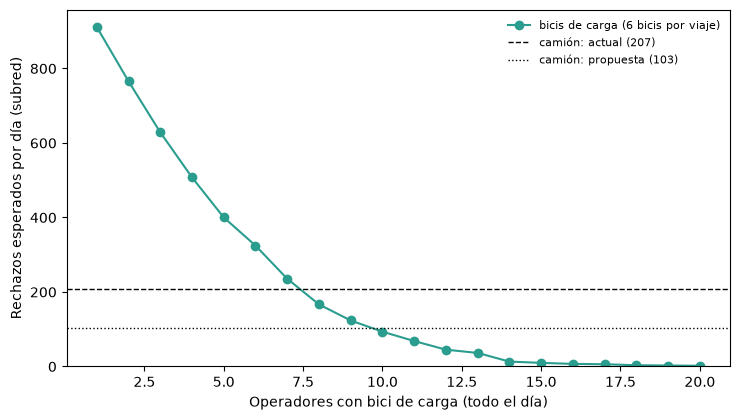

,271-272,273-274,014,027,018,rechazos,sin bici,sin dock,bicis movidas
operadores,,,,,,,,,
1,1.0,0.0,0.0,0.0,0.0,911.6,320.8,590.8,192.0
2,2.0,0.0,0.0,0.0,0.0,765.7,256.3,509.4,340.8
3,2.0,0.5,0.5,0.0,0.0,628.8,198.7,430.0,502.6
4,3.0,0.5,0.5,0.0,0.0,507.7,147.4,360.3,624.0
5,3.0,1.0,0.5,0.0,0.5,400.2,104.4,295.9,749.2
6,4.0,1.0,0.5,0.0,0.5,324.6,73.7,250.9,824.0
7,5.0,1.0,0.5,0.0,0.5,235.6,44.7,190.9,911.2
8,5.0,1.0,1.0,0.5,0.5,166.7,25.9,140.9,1000.2
9,6.0,1.0,1.0,0.5,0.5,123.5,20.7,102.8,1042.2


In [6]:
def asignar(total, tabla=por_est, columna="rechazos"):
    """Reparto óptimo de `total` operadores entre las estaciones (programación dinámica tipo mochila, en medios operadores)."""
    U = int(round(2 * total))
    mejor = {0: (0.0, [])}
    for est in ORDEN:
        opciones = tabla[tabla["estación"] == est].set_index("operadores")[columna]
        nuevo = {}
        for usado, (c, asig) in mejor.items():
            for k, v in opciones.items():
                u = usado + int(round(2 * k))
                if u <= U and (u not in nuevo or c + v < nuevo[u][0]):
                    nuevo[u] = (c + v, asig + [k])
        mejor = nuevo
    c, asig = min(mejor.values(), key=lambda t: t[0])
    return dict(zip(ORDEN, asig))

filas = []
for total in range(1, 21):
    asig = asignar(total)
    r = pd.DataFrame([evaluar(planes[(e, k)]) for e, k in asig.items()]).drop(columns="visitas").sum()
    filas.append({"operadores": total, **{e: asig[e] for e in ORDEN}, "rechazos": r.rechazos,
                  "sin bici": r["sin bici"], "sin dock": r["sin dock"], "bicis movidas": r["bicis dejadas"] + r["bicis sacadas"]})
flota = pd.DataFrame(filas).set_index("operadores")
flota.round(1).to_csv(DIR_TABLAS / "bdb_flota.csv")

def iguala(meta):
    ok = flota[flota.rechazos <= meta]
    return ok.index.min() if len(ok) else None
print(f"Operadores para igualar al camión actual ({cam_cap['actual']:.0f} rechazos): {iguala(cam_cap['actual'])}; "
      f"a la propuesta con camión ({cam_cap['propuesta']:.0f}): {iguala(cam_cap['propuesta'])}")

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(flota.index, flota.rechazos, marker="o", color="#2a9d8f", label="bicis de carga (6 bicis por viaje)")
for nombre, ls in [("actual", "--"), ("propuesta", ":")]:
    ax.axhline(cam_cap[nombre], color="black", ls=ls, lw=1, label=f"camión: {nombre} ({cam_cap[nombre]:.0f})")
ax.set_xlabel("Operadores con bici de carga (todo el día)"); ax.set_ylabel("Rechazos esperados por día (subred)")
ax.set_ylim(0, None); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(DIR_FIG / "bdb_flota.png", dpi=150, bbox_inches="tight"); plt.show()
flota.round(1)

**Resultados**

- Con **8 operadores** las bicis de carga ya tienen menos rechazos que el camión actual: 167 contra 207.
- Con **10 operadores** quedan por debajo de la propuesta con camión: 94 contra 103. Con 14 bajan a 13.
- Casi la mitad de la flota va a la 271-272 (5 de 8, 6 de 10). El resto se reparte entre la 273-274 y la 014, con medio operador para la 027 y la 018.
- Las bicis movidas en el día son casi las mismas que con el camión: unas 1,000 con 8 operadores y 1,070 con 10, contra 1,008 del camión.
- Con pocos operadores lo que queda son sobre todo rechazos sin dock: en la tarde la 271-272 recibe más bicis de las que se pueden sacar de 6 en 6.

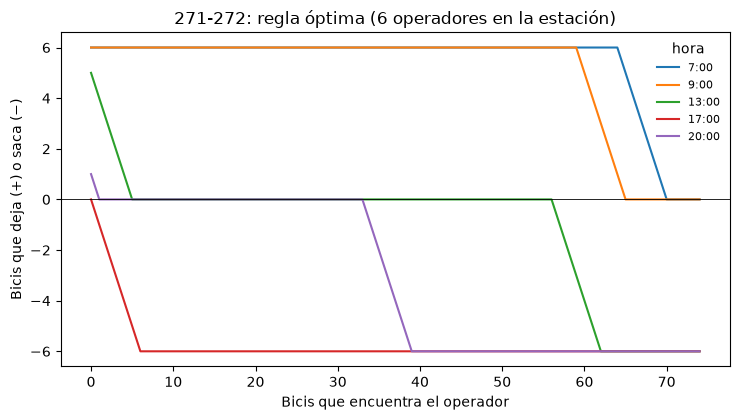

In [7]:
# Cómo se ve la regla óptima: con cuántas bicis deja el operador la 271-272 según lo que encuentra, a distintas horas
FLOTA_FIG = 10
plan = planes[("271-272", flota.loc[FLOTA_FIG, "271-272"])]
N = plan["N"]; n = np.arange(N + 1)
fig, ax = plt.subplots(figsize=(7.5, 4.3))
for hora in [7, 9, 13, 17, 20]:
    j = int(np.argmin(np.abs(np.array(plan["cortes"]) - (hora - 5) * PASOS)))
    ax.plot(n, plan["regla"][j] - n, label=f"{hora}:00")
ax.axhline(0, color="black", lw=0.6)
ax.set_xlabel("Bicis que encuentra el operador"); ax.set_ylabel("Bicis que deja (+) o saca (−)")
ax.set_title(f"271-272: regla óptima ({flota.loc[FLOTA_FIG, '271-272']:g} operadores en la estación)"); ax.legend(frameon=False, fontsize=8, title="hora")
fig.tight_layout(); fig.savefig(DIR_FIG / "bdb_regla.png", dpi=150, bbox_inches="tight"); plt.show()

**Resultados**

La regla óptima es sencilla, de tipo umbral:
- En la mañana (7 y 9 h), si la estación tiene menos de unas 60 bicis, el operador deja las 6 que trae. Llena la estación antes de la ola de retiros.
- A las 17 h hace lo contrario: saca 6 casi siempre y solo deja bicis si la encuentra vacía.
- A mediodía y en la noche (13 y 20 h) solo actúa en los extremos: deja bicis si está casi vacía y saca si tiene más de ~35 a 56. En medio no hace nada, por el costo $w$.

En la práctica, el operador solo necesita una tabla de umbrales por hora.

In [8]:
# Balance de la flota de 10: bicis que dejan (+) o sacan (−) los operadores en cada zona, por franja del día
filas = []
for e in ORDEN:
    for m, deja, saca in evaluar(planes[(e, flota.loc[FLOTA_FIG, e])])["visitas"]:
        filas.append({"zona": SUBRED[e], "franja": "mañana (5 a 13 h)" if m < 8 * PASOS else "tarde (13 a 24 h)", "neto": deja - saca})
bal = pd.DataFrame(filas).pivot_table(index="franja", columns="zona", values="neto", aggfunc="sum").reindex(["mañana (5 a 13 h)", "tarde (13 a 24 h)"])
bal["neto subred"] = bal.sum(axis=1)
bal.round(0)

zona,Buenavista,Reforma,neto subred
franja,,,
mañana (5 a 13 h),333.0,-127.0,206.0
tarde (13 a 24 h),-496.0,94.0,-401.0


**Resultados**

- En la mañana la flota deja unas 333 bicis en Buenavista y saca 127 de Reforma. En la tarde saca 496 de Buenavista y deja 94 en Reforma.
- La subred sola no se equilibra: en la mañana hacen falta unas 206 bicis más y en la tarde sobran unas 401. Esas bicis las dan y las reciben las vecinas de Reforma, que en la mañana tienen bicis de sobra y en la tarde las necesitan (sección 1).
- Por eso el viaje base es Reforma ↔ Buenavista. Un viaje sirve a las dos zonas a la vez: saca bicis donde sobran y las deja donde faltan. En el modelo cada estación cuenta sus operadores por separado, así que el número de operadores puede estar algo sobreestimado.

### 3.3 Sensibilidad a la duración del viaje

El tiempo de 30 min es una estimación: unos 6 min para cargar y descargar 6 bicis, más ir y volver unos 2.5 km. Se prueban otros valores:
- 12 min: con una bodega a unos 500 m de cada zona, que el camión surte en la noche;
- 20 min;
- 45 min: con tráfico o esperas.

In [9]:
# Sensibilidad al tiempo de cada viaje: 12 min (bodega a ~500 m), 20 min (~1.2 km), 30 min (base, Reforma ↔ Buenavista), 45 min (con tráfico o esperas)
filas = []
for t in [12, 20, 30, 45]:
    tab = []
    for est in ORDEN:
        for k in NIVELES:
            plan = planes[(est, k)] if t == T_CICLO else optimizar_mdp(est, k, t_ciclo=t)
            tab.append({"estación": est, "operadores": k, "rechazos": evaluar(plan)["rechazos"]})
    tab = pd.DataFrame(tab)
    for total in [4, 6, 8, 10, 12, 14]:
        asig = asignar(total, tab)
        rech = sum(tab[(tab["estación"] == e) & (tab.operadores == k)].rechazos.iloc[0] for e, k in asig.items())
        filas.append({"minutos por viaje": t, "operadores": total, "rechazos": rech})
sens = pd.DataFrame(filas).pivot(index="operadores", columns="minutos por viaje", values="rechazos")
sens.round(0).to_csv(DIR_TABLAS / "bdb_sensibilidad.csv")
sens.round(0).rename_axis(columns="minutos por viaje: rechazos")

minutos por viaje: rechazos,12,20,30,45
operadores,,,,
4,115.0,340.0,508.0,665.0
6,8.0,140.0,325.0,488.0
8,2.0,33.0,167.0,362.0
10,2.0,12.0,93.0,270.0
12,2.0,3.0,45.0,181.0
14,1.0,2.0,13.0,106.0


**Resultados**

- La duración del viaje pesa mucho. Para igualar al camión actual (207) bastan 4 operadores con viajes de 12 min; hacen falta 5 o 6 con viajes de 20 min, 8 con viajes de 30 min y 12 con viajes de 45 min.
- Con una bodega cerca de cada zona (12 min por viaje), 6 operadores dejan los rechazos en 8 por día. Pero alguien tiene que surtir esa bodega, y eso vuelve a ser un camión.

## 4. Simulación

Se usa el mismo simulador evento por evento de `simulacion.ipynb` (Gillespie con lotes), con los mismos escenarios de demanda (baja, base y alta) y la misma variación entre días. Lo único que cambia son las visitas: cada operador llega en su horario, ve $x$ y deja la estación con $y(x)$ de la regla óptima.

Las reglas se diseñaron con la demanda de septiembre y no se ajustan a cada escenario, igual que con el camión.

Se prueban flotas de 6, 8, 10 y 12 operadores, cada una con su reparto óptimo de la sección 3.2. Los resultados del camión se toman de `sim_escenarios.csv`.

### 4.1 Validación contra Kolmogorov

In [10]:
# Escenarios y variación entre días: los mismos de simulacion.ipynb
ESC = pd.read_csv(DIR_TABLAS / "escenarios.csv")
F_ESC = {"baja": ESC.factor.min(), "base": 1.0, "alta": ESC.factor.max()}
ESC["escenario"] = [min(F_ESC, key=lambda s: abs(F_ESC[s] - f)) for f in ESC.factor]
PROB = ESC.escenario.value_counts(normalize=True).reindex(list(F_ESC)).fillna(0)
var = pd.read_csv(DIR_TABLAS / "sim_variacion_dias.csv", dtype={"estacion": str})
CV = var.pivot(index="estacion", columns="proceso", values="CV entre días").reindex(index=ORDEN, columns=["devolucion", "retiro"]).to_numpy()
LAM = {e: tasas_estacion(e)[0] for e in ORDEN}
MU = {e: tasas_estacion(e)[1] for e in ORDEN}

def simular_dia(planes_dia, f, G, rng):
    """Un día de la subred evento por evento (Gillespie con lotes), con las visitas de las bicis de carga.
    En cada visita el operador ve x y deja la estación con regla[x]. Devuelve por estación:
    [sin bici, sin dock, retiros hechos, devoluciones hechas, bicis dejadas, bicis sacadas]."""
    out = np.zeros((len(ORDEN), 6))
    for i, est in enumerate(ORDEN):
        plan = planes_dia[est]
        N, b_dev, b_ret = DOCKS[est], B[(est, "devolucion")], B[(est, "retiro")]
        visitas = [(m / PASOS, y) for m, y in zip(plan["cortes"], plan["regla"])]
        iv, x, t = 0, plan["x0"], 0.0
        for k in range(len(HORAS)):
            g_dev, g_ret = LAM[est][k] * f * G[i, 0] / b_dev, MU[est][k] * f * G[i, 1] / b_ret
            tot = g_dev + g_ret
            while True:
                t_ev = t + rng.exponential(1 / tot) if tot > 0 else np.inf
                while iv < len(visitas) and visitas[iv][0] <= min(t_ev, k + 1):      # visita antes del siguiente lote
                    nuevo = int(visitas[iv][1][x]); iv += 1
                    out[i, 4] += max(nuevo - x, 0); out[i, 5] += max(x - nuevo, 0); x = nuevo
                if t_ev >= k + 1:
                    t = k + 1
                    break
                t = t_ev
                if rng.random() < g_dev / tot:
                    m = rng.geometric(1 / b_dev); entra = min(m, N - x); x += entra
                    out[i, 1] += m - entra; out[i, 3] += entra
                else:
                    m = rng.geometric(1 / b_ret); sale = min(m, x); x -= sale
                    out[i, 0] += m - sale; out[i, 2] += sale
    return out

def simular(planes_dia, n_dias, f=1.0, cv=None, semilla=0):
    rng = np.random.default_rng(semilla)
    G = np.ones((n_dias, len(ORDEN), 2))
    if cv is not None:
        forma = 1 / np.maximum(cv, 1e-6) ** 2
        G = np.where(cv > 0, rng.gamma(forma, 1 / forma, size=G.shape), 1.0)
    return np.array([simular_dia(planes_dia, f, g, rng) for g in G])

# Alternativas con bicis de carga: el reparto óptimo de cada tamaño de flota
FLOTAS = [6, 8, 10, 12]
ALT_BDB = {f"bicis de carga ({o} operadores)": {e: planes[(e, flota.loc[o, e])] for e in ORDEN} for o in FLOTAS}
N_SIM = 1000

In [11]:
# Validación: sin variación entre días, el Monte Carlo debe dar lo mismo que Kolmogorov
t0 = time.time()
filas = []
for nombre, pl in ALT_BDB.items():
    s = simular(pl, N_SIM, semilla=7)
    rech = s[:, :, 0] + s[:, :, 1]
    for i, est in enumerate(ORDEN):
        m, ee = rech[:, i].mean(), rech[:, i].std(ddof=1) / np.sqrt(N_SIM)
        k = evaluar(pl[est])["rechazos"]
        filas.append({"alternativa": nombre, "estación": est, "Kolmogorov": k, "Monte Carlo": m,
                      "IC 95 %": f"{m - 1.96 * ee:.1f} a {m + 1.96 * ee:.1f}", "dentro del IC": abs(m - k) <= 1.96 * ee})
val = pd.DataFrame(filas)
val.round(1).to_csv(DIR_TABLAS / "bdb_validacion.csv", index=False)
print(f"{val['dentro del IC'].sum()} de {len(val)} comparaciones dentro del IC 95 %  ({time.time() - t0:.0f} s)")
val.round(1)

20 de 20 comparaciones dentro del IC 95 %  (15 s)


,alternativa,estación,Kolmogorov,Monte Carlo,IC 95 %,dentro del IC
0,bicis de carga (6 operadores),271-272,168.2,167.6,165.5 a 169.7,True
1,bicis de carga (6 operadores),273-274,31.1,30.8,29.7 a 31.8,True
2,bicis de carga (6 operadores),014,56.5,56.2,55.2 a 57.2,True
3,bicis de carga (6 operadores),027,48.6,48.1,46.8 a 49.4,True
4,bicis de carga (6 operadores),018,20.3,20.3,19.5 a 21.1,True
5,bicis de carga (8 operadores),271-272,79.2,78.7,77.1 a 80.4,True
6,bicis de carga (8 operadores),273-274,31.1,30.8,29.7 a 31.8,True
7,bicis de carga (8 operadores),014,28.2,27.8,27.0 a 28.6,True
8,bicis de carga (8 operadores),027,8.0,8.3,7.7 a 8.9,True
9,bicis de carga (8 operadores),018,20.3,20.3,19.5 a 21.1,True


**Resultados**

- Las 20 comparaciones (4 flotas × 5 estaciones) caen dentro del IC de 95 %. El simulador aplica bien la regla de las bicis de carga.

### 4.2 Escenarios de demanda

1,000 días simulados por alternativa y escenario.

(47 s)


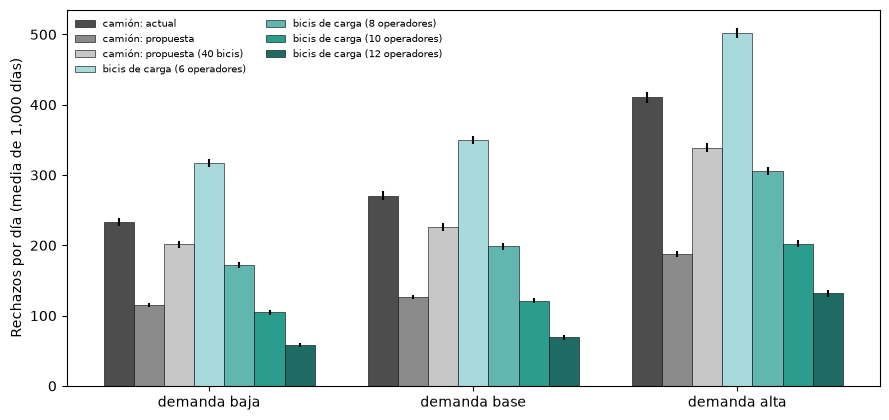

escenario,baja,base,alta
política,,,
camión: actual,232.7,270.6,410.9
camión: propuesta,115.3,126.4,187.7
camión: propuesta (40 bicis),201.6,226.2,339.0
bicis de carga (6 operadores),317.3,349.4,502.4
bicis de carga (8 operadores),172.5,199.0,305.9
bicis de carga (10 operadores),104.7,121.4,202.1
bicis de carga (12 operadores),58.3,69.2,131.5


In [12]:
t0 = time.time()
filas, res = [], {}
for e_i, (esc, f) in enumerate(F_ESC.items()):
    for a_i, (nombre, pl) in enumerate(ALT_BDB.items()):
        s = simular(pl, N_SIM, f=f, cv=CV, semilla=500 + 10 * e_i + a_i)
        res[(nombre, esc)] = s
        rech, hechos = (s[:, :, 0] + s[:, :, 1]).sum(1), (s[:, :, 2] + s[:, :, 3]).sum(1)
        filas.append({"política": nombre, "escenario": esc, "rechazos (media)": rech.mean(),
                      "IC 95 %": 1.96 * rech.std(ddof=1) / np.sqrt(N_SIM), "rechazos P95": np.percentile(rech, 95),
                      "% demanda atendida": 100 * hechos.sum() / (hechos.sum() + rech.sum()),
                      "bicis movidas": (s[:, :, 4] + s[:, :, 5]).sum(1).mean()})
print(f"({time.time() - t0:.0f} s)")
bdb_sim = pd.DataFrame(filas)
camiones = cam_sim[cam_sim["política"].isin(["actual", "propuesta", "propuesta (camión de 40)"])].replace(
    {"política": {"actual": "camión: actual", "propuesta": "camión: propuesta", "propuesta (camión de 40)": "camión: propuesta (40 bicis)"}})
todo = pd.concat([camiones, bdb_sim], ignore_index=True)
todo.round(1).to_csv(DIR_TABLAS / "bdb_escenarios.csv", index=False)
ORDEN_ALT = list(camiones["política"].unique()) + list(ALT_BDB)

fig, ax = plt.subplots(figsize=(9, 4.3))
x = np.arange(len(F_ESC)); ancho = 0.8 / len(ORDEN_ALT)
for i, alt in enumerate(ORDEN_ALT):
    v = todo[todo["política"] == alt].set_index("escenario").reindex(list(F_ESC))
    color = ["#4d4d4d", "#8a8a8a", "#c7c7c7", "#a8dadc", "#62b6b0", "#2a9d8f", "#1d6b62"][i]
    ax.bar(x + i * ancho, v["rechazos (media)"], ancho, yerr=v["IC 95 %"], color=color, edgecolor="black", lw=0.4, label=alt)
ax.set_xticks(x + ancho * (len(ORDEN_ALT) - 1) / 2); ax.set_xticklabels([f"demanda {e}" for e in F_ESC])
ax.set_ylabel("Rechazos por día (media de 1,000 días)"); ax.legend(frameon=False, fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(DIR_FIG / "bdb_escenarios.png", dpi=150, bbox_inches="tight"); plt.show()
todo.pivot(index="política", columns="escenario", values="rechazos (media)").reindex(index=ORDEN_ALT, columns=list(F_ESC)).round(1)

**Resultados**

Rechazos por día, con variación entre días:

| | baja | base | alta |
|---|---|---|---|
| camión: actual | 233 | 271 | 411 |
| camión: propuesta | 115 | 126 | 188 |
| camión: propuesta (40 bicis) | 202 | 226 | 339 |
| bicis de carga, 8 operadores | 173 | 199 | 306 |
| bicis de carga, 10 operadores | 105 | 121 | 202 |
| bicis de carga, 12 operadores | 58 | 69 | 132 |

- Con 8 operadores le ganan al camión actual y al camión de 40 en los tres escenarios.
- Con 10 operadores quedan parecidas a la propuesta con camión: un poco mejores en demanda baja y base, y un poco peores en alta (202 contra 188). La capacidad por hora de los operadores es fija; el camión puede mover mucho en una sola visita.
- En los días malos el camión grande aguanta mejor: el P95 en el escenario base es 239 con 10 operadores y 202 con la propuesta con camión.
- Con 6 operadores no alcanzan: quedan peor que el camión actual.

## 5. Criterios de decisión

Matriz de costos: rechazos esperados por día en cada escenario. Se usan los mismos criterios de `simulacion.ipynb`: valor esperado, Laplace, Wald, Hurwicz ($\alpha = 0.5$) y Savage.

In [13]:
M = todo.pivot(index="política", columns="escenario", values="rechazos (media)").reindex(index=ORDEN_ALT, columns=list(F_ESC))
ALFA = 0.5
arrep = M - M.min()
criterios = pd.DataFrame({
    "Valor esperado": M @ PROB,
    "Laplace": M.mean(axis=1),
    "Wald (peor caso)": M.max(axis=1),
    f"Hurwicz (α = {ALFA})": ALFA * M.min(axis=1) + (1 - ALFA) * M.max(axis=1),
    "Savage (máx. arrepentimiento)": arrep.max(axis=1),
})
criterios.round(1).to_csv(DIR_TABLAS / "bdb_criterios.csv")
print("Elegida por cada criterio (menor es mejor):")
print(criterios.idxmin().to_string())
criterios.round(1)

Elegida por cada criterio (menor es mejor):
Valor esperado                   bicis de carga (12 operadores)
Laplace                          bicis de carga (12 operadores)
Wald (peor caso)                 bicis de carga (12 operadores)
Hurwicz (α = 0.5)                bicis de carga (12 operadores)
Savage (máx. arrepentimiento)    bicis de carga (12 operadores)


,Valor esperado,Laplace,Wald (peor caso),Hurwicz (α = 0.5),Savage (máx. arrepentimiento)
política,,,,,
camión: actual,318.7,304.7,410.9,321.8,279.4
camión: propuesta,148.3,143.1,187.7,151.5,57.2
camión: propuesta (40 bicis),265.8,255.6,339.0,270.3,207.5
bicis de carga (6 operadores),403.3,389.7,502.4,409.8,370.9
bicis de carga (8 operadores),236.0,225.8,305.9,239.2,174.4
bicis de carga (10 operadores),149.9,142.7,202.1,153.4,70.6
bicis de carga (12 operadores),91.5,86.4,131.5,94.9,0.0


**Resultados**

- Los cinco criterios eligen 12 operadores, porque esa flota gana en los tres escenarios. Eso era de esperarse: tener más operadores siempre ayuda. La comparación útil es con flotas de un tamaño parecido al del camión.
- Por valor esperado, **10 operadores (150 rechazos) quedan empatados con la propuesta con camión (148)** y muy por debajo del camión actual (319). Con 8 operadores (236) quedan entre el camión actual y el camión de 40 (266).
- Ninguno de estos criterios incluye el costo. Para decidir entre camión y bicis de carga hace falta comparar cuánto cuestan 10 operadores contra un camión con chofer y ayudante.

## 6. Rutas de bicis de carga

En las secciones 2 a 5 cada estación tenía sus propios operadores, y cada viaje duraba 30 min. En la realidad un operador sigue una **ruta**: carga bicis donde sobran, las lleva a donde faltan y sigue. Así un viaje puede servir a dos estaciones a la vez, pero solo puede dejar las bicis que trae.

Aquí se busca la mejor ruta, o el mejor conjunto de rutas, solo con bicis de carga:

- **Paradas:** las 5 estaciones y "VR", las estaciones vecinas de Reforma (sección 1). VR puede dar bicis en las horas en que les sobran (5 a 12 h) y recibirlas cuando les faltan (13 a 24 h). Las vecinas de Buenavista no sirven, porque se vacían y se llenan al mismo tiempo que Buenavista.
- **Tiempos:** se calculan con las coordenadas de las estaciones. La distancia en línea recta se alarga 30 % por las calles, la bici va a 12 km/h, cada parada toma 1 min y cada bici que se carga o descarga, 0.5 min.
- **Rutas candidatas:** todas cruzan de la zona de Reforma a Buenavista, porque las dos zonas se complementan. Son 18 combinaciones de paradas, cada una en su orden más corto.
- **Decisión en cada parada:** el operador ve cuántas bicis hay en la estación y cuántas lleva. Las estaciones se pueden ver en la app. Elige con cuántas dejar la estación con *un paso adelante*: suma el costo de la estación donde está y el de la siguiente estación de su ruta según la carga con que llegaría. Los dos costos salen de la programación dinámica de la sección 2 (la función de valor), calculada con la frecuencia de visitas que le da la ruta.
- **Evaluación:** como las estaciones quedan conectadas por la carga del operador, ya no se puede usar Kolmogorov por estación. Cada diseño se evalúa con el simulador Monte Carlo, ahora con todas las estaciones y los operadores moviéndose en el mismo reloj.

### 6.1 Rutas candidatas

In [14]:
import heapq
from itertools import permutations

# Paradas posibles: las 5 estaciones y "VR" = las vecinas de Reforma (sección 1), ubicadas en su centro.
# Las vecinas de Buenavista no sirven como parada: se vacían y se llenan al mismo tiempo que Buenavista.
VR = "VR"
info[VR] = tuple(np.mean([info[e] for e in VEC["Reforma"]], axis=0))
VR_SIGNO = np.sign(neto.loc[VEC["Reforma"]].sum().to_numpy())     # por hora: +1 les sobran bicis (pueden dar), −1 les faltan (pueden recibir)

VEL, CALLE = 12, 1.3              # km/h de una bici de carga; las calles alargan la línea recta ~30 %
MIN_PARADA, MIN_BICI = 1.0, 0.5   # minutos por parada y por bici que se carga o descarga
PARADAS = ORDEN + [VR]
TIEMPO = {(a, b): km(a, b) * CALLE / VEL * 60 for a in PARADAS for b in PARADAS}     # minutos de viaje

def ciclo(ruta, bicis=3):
    """Minutos de una vuelta completa, suponiendo `bicis` cargadas o descargadas en cada parada."""
    return sum(TIEMPO[a, b] for a, b in zip(ruta, ruta[1:] + ruta[:1])) + len(ruta) * (MIN_PARADA + MIN_BICI * bicis)

def mejor_orden(paradas):
    """El orden más corto para recorrer las paradas en ciclo (son pocas: se prueban todas)."""
    p0 = paradas[0]
    resto = min(permutations(paradas[1:]), key=lambda o: ciclo((p0,) + o, 0))
    return (p0,) + resto

# Rutas candidatas: siempre cruzan de Reforma a Buenavista, porque las dos zonas se complementan (sección 1)
LADO_R = [(VR,), (VR, "027", "018"), (VR, "014"), (VR, "014", "027", "018"), ("027", "018"), ("014", "027", "018")]
LADO_B = [("271-272",), ("273-274",), ("271-272", "273-274")]
CANDIDATAS = [mejor_orden(r + b) for r in LADO_R for b in LADO_B]
nombre_ruta = lambda r: " → ".join(r) + " → " + r[0]
pd.DataFrame({"ruta": [nombre_ruta(r) for r in CANDIDATAS],
              "km por vuelta": [sum(km(a, b) * CALLE for a, b in zip(r, r[1:] + r[:1])) for r in CANDIDATAS],
              "minutos por vuelta": [ciclo(r) for r in CANDIDATAS]}).round(1)

,ruta,km por vuelta,minutos por vuelta
0,VR → 271-272 → VR,6.2,36.1
1,VR → 273-274 → VR,5.9,34.6
2,VR → 271-272 → 273-274 → VR,6.2,38.6
3,VR → 018 → 027 → 271-272 → VR,6.3,41.5
4,VR → 018 → 027 → 273-274 → VR,6.0,40.0
5,VR → 018 → 027 → 273-274 → 271-272 → VR,6.3,44.0
6,VR → 014 → 271-272 → VR,8.0,47.5
7,VR → 014 → 273-274 → VR,7.7,46.0
8,VR → 014 → 271-272 → 273-274 → VR,8.0,50.0
9,VR → 014 → 271-272 → 027 → 018 → VR,8.1,52.9


In [15]:
# Camión dentro de Kolmogorov (para la combinación de la sección 7): matriz de lo que hace en cada minuto
cam_h = pd.read_csv(DIR_TABLAS / "camion_actual_hora.csv", dtype={"estacion": str}).set_index(["tipo", "estacion"])
cam_h.columns = cam_h.columns.astype(int)
NETO_ACTUAL = cam_h.loc["deja"] - cam_h.loc["saca"]
cam_vis = pd.read_csv(DIR_TABLAS / "camion_propuesta.csv", dtype={"estación": str})
cam_vis["minuto"] = cam_vis.hora.str.split(":").map(lambda h: (int(h[0]) - 5) * 60 + int(h[1]))

def acciones_camion(nombre, est):
    """[(minuto, tipo, valor)]: 'mover' = deja (o saca) esa cantidad; 'nivel' = deja la estación con ese nivel (camión de 40)."""
    if nombre == "actual":
        return [(k * PASOS + m, "mover", NETO_ACTUAL.loc[est, h] * 5 / PASOS)
                for k, h in enumerate(HORAS) if NETO_ACTUAL.loc[est, h] != 0 for m in range(2, PASOS, 5)]
    if nombre == "propuesta (40)":
        v = cam_vis[cam_vis["estación"] == est]
        return list(zip(v.minuto, ["nivel"] * len(v), v["deja la estación con"]))
    return []

def matriz_camion(tipo, v, N):
    n, T = np.arange(N + 1), np.zeros((N + 1, N + 1))
    if tipo == "mover":
        k = int(np.floor(v))
        for kk, peso in [(k, 1 - (v - k)), (k + 1, v - k)]:
            T[n, np.clip(n + kk, 0, N)] += peso
    else:
        T[n, np.clip(v, n - 40, n + 40)] = 1
    return T

_valores = {}
def valor_estacion(est, delta, camion=None):
    """Regla de la estación si recibe una visita cada `delta` minutos (MDP de la sección 2, con o sin camión).
    G[j, y]: rechazos esperados de la visita j al final si se deja con y.
    H[j, x, l]: lo mejor que se puede lograr en la visita j si el operador llega con l bicis cargadas y encuentra x."""
    clave = (est, delta, camion)
    if clave not in _valores:
        N = int(DOCKS[est])
        cam = {m: matriz_camion(t, v, N) for m, t, v in acciones_camion(camion, est)} if camion else None
        plan = optimizar_mdp(est, 0, cortes=list(range(delta, MIN_DIA, delta)) if delta else [], camion=cam)
        G = np.array(plan["valor"]) if delta else np.zeros((0, N + 1))
        H = np.full((len(G), N + 1, CAP + 1), np.inf)
        for x in range(N + 1):
            for l in range(CAP + 1):
                lo, hi = max(0, x - CAP, x + l - CAP), min(N, x + l)
                H[:, x, l] = (W * np.abs(np.arange(lo, hi + 1) - x)[None, :] + G[:, lo:hi + 1]).min(1) if len(G) else 0
        _valores[clave] = {"G": G, "H": H, "delta": delta, "x0": plan["x0"], "N": N}
    return _valores[clave]

REJILLA = np.array([3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40, 50, 60])
def intervalos(diseno):
    """Minutos promedio entre visitas a cada estación según cuántos operadores recorren cada ruta."""
    tasa = {e: 0.0 for e in ORDEN}
    for r, n in diseno.items():
        for e in r:
            if e in tasa:
                tasa[e] += n / ciclo(r)
    return {e: int(REJILLA[np.abs(REJILLA - 1 / t).argmin()]) if t > 0 else None for e, t in tasa.items()}

In [16]:
IDX = {e: i for i, e in enumerate(ORDEN)}
LAM_A, MU_A = np.array([LAM[e] for e in ORDEN]), np.array([MU[e] for e in ORDEN])
BD = np.array([B[(e, "devolucion")] for e in ORDEN]); BR = np.array([B[(e, "retiro")] for e in ORDEN])
NN = np.array([int(DOCKS[e]) for e in ORDEN])

def preparar_rutas(diseno, camion=None):
    """Lo que necesita el simulador: regla de cada estación, operadores con su ruta y hora de salida, y el camión."""
    D = intervalos(diseno)
    V = {e: valor_estacion(e, D[e], camion) for e in ORDEN}
    ops = []
    for r, n in diseno.items():
        for k in range(n):
            ops.append((r, k * ciclo(r) / n / PASOS))           # salen escalonados desde la primera parada
    cam = [(m / PASOS, IDX[e], t, v) for e in ORDEN for m, t, v in acciones_camion(camion, e)] if camion else []
    return {"V": V, "ops": ops, "camion": cam, "x0": np.array([V[e]["x0"] for e in ORDEN])}

def siguiente_estacion(ruta, pos, t_min):
    """Próxima estación de la ruta después de la parada `pos`, cuándo se llega y si en medio se pasa por VR."""
    t, vr, p = t_min, False, pos
    for _ in range(len(ruta)):
        q = (p + 1) % len(ruta)
        t += TIEMPO[ruta[p], ruta[q]] + MIN_PARADA + MIN_BICI * 3
        if ruta[q] == VR:
            vr = True
        else:
            return ruta[q], t, vr
        p = q
    return None, t, vr

def mirar_adelante(V, x, ruta, pos, t_min):
    """Valor, para cada carga l = 0..6, de llegar a la próxima estación con l bicis (un paso adelante).
    Si en medio está VR, ahí se puede ajustar la carga en el sentido que permita esa hora."""
    est, t, vr = siguiente_estacion(ruta, pos, t_min)
    if est is None:
        return np.zeros(CAP + 1)
    v = V[est]
    j = min(max(int(round(t / v["delta"])) - 1, 0), len(v["G"]) - 1)
    h = v["H"][j, x[IDX[est]]]
    if vr:
        s = VR_SIGNO[min(int(t // PASOS), len(HORAS) - 1)]
        if s > 0:                                    # VR puede dar bicis: se puede llegar con más
            h = np.minimum.accumulate(h[::-1])[::-1]
        elif s < 0:                                  # VR puede recibir: se puede llegar con menos
            h = np.minimum.accumulate(h)
    return h

def simular_dia_rutas(ctx, f, G, rng):
    """Un día de la subred con bicis de carga en ruta (y camión, si hay), evento por evento.
    Devuelve por estación: [sin bici, sin dock, retiros, devoluciones, bici de carga deja, bici de carga saca, camión deja, camión saca]
    y las bicis que las bicis de carga toman de / dejan en VR."""
    V, x = ctx["V"], ctx["x0"].copy()
    out, vr = np.zeros((len(ORDEN), 8)), np.zeros(2)
    eventos, cont = [], 0
    for te, i, tipo, v in ctx["camion"]:
        eventos.append((te, cont, ("camión", i, tipo, v))); cont += 1
    for o, (r, t0) in enumerate(ctx["ops"]):
        eventos.append((t0, cont, ("op", o, 0))); cont += 1
    heapq.heapify(eventos)
    carga = np.zeros(len(ctx["ops"]), dtype=int)
    t = 0.0
    for k in range(len(HORAS)):
        tasas_k = np.concatenate([LAM_A[:, k] * f * G[:, 0] / BD, MU_A[:, k] * f * G[:, 1] / BR])
        tot = tasas_k.sum(); acum = np.cumsum(tasas_k) / tot
        while True:
            t_ev = t + rng.exponential(1 / tot)
            while eventos and eventos[0][0] <= min(t_ev, k + 1):
                te, _, ev = heapq.heappop(eventos)
                if ev[0] == "camión":
                    _, i, tipo, v = ev
                    if tipo == "mover":
                        v = int(np.floor(v)) + (rng.random() < v - np.floor(v))
                        nuevo = min(max(x[i] + v, 0), NN[i])
                    else:
                        nuevo = min(max(v, x[i] - 40), x[i] + 40)
                    out[i, 6] += max(nuevo - x[i], 0); out[i, 7] += max(x[i] - nuevo, 0); x[i] = nuevo
                    continue
                _, o, pos = ev
                ruta, L, t_min = ctx["ops"][o][0], carga[o], te * PASOS
                parada = ruta[pos]
                adelante = mirar_adelante(V, x, ruta, pos, t_min)
                if parada == VR:                                       # ajusta su carga con las vecinas de Reforma
                    s = VR_SIGNO[min(k, len(HORAS) - 1)]
                    ls = np.arange(CAP + 1)
                    ok = (ls >= L) if s > 0 else (ls <= L) if s < 0 else (ls == L)
                    nueva = int(ls[ok][adelante[ok].argmin()])
                    vr += [max(nueva - L, 0), max(L - nueva, 0)]       # [tomadas de VR, dejadas en VR]
                    movidas = abs(nueva - L); carga[o] = nueva
                else:                                                  # decide con cuántas deja la estación
                    i = IDX[parada]; v = V[parada]
                    j = min(max(int(round(t_min / v["delta"])) - 1, 0), len(v["G"]) - 1)
                    ys = np.arange(max(0, x[i] - CAP, x[i] + L - CAP), min(NN[i], x[i] + L) + 1)
                    costo = W * np.abs(ys - x[i]) + v["G"][j, ys] + adelante[L + x[i] - ys]
                    y = int(ys[costo.argmin()])
                    movidas = abs(y - x[i]); carga[o] = L + x[i] - y
                    out[i, 4] += max(y - x[i], 0); out[i, 5] += max(x[i] - y, 0); x[i] = y
                q = (pos + 1) % len(ruta)
                t_sig = te + (MIN_PARADA + MIN_BICI * movidas + TIEMPO[parada, ruta[q]]) / PASOS
                heapq.heappush(eventos, (t_sig, cont, ("op", o, q))); cont += 1
            if t_ev >= k + 1:
                t = k + 1
                break
            t = t_ev
            idx = int(np.searchsorted(acum, rng.random()))
            i = idx % len(ORDEN)
            if idx < len(ORDEN):
                m = rng.geometric(1 / BD[i]); entra = min(m, NN[i] - x[i]); x[i] += entra
                out[i, 1] += m - entra; out[i, 3] += entra
            else:
                m = rng.geometric(1 / BR[i]); sale = min(m, x[i]); x[i] -= sale
                out[i, 0] += m - sale; out[i, 2] += sale
    return out, vr

def simular_rutas(diseno, n_dias, f=1.0, cv=None, semilla=0, camion=None):
    ctx = preparar_rutas(diseno, camion)
    rng = np.random.default_rng(semilla)
    G = np.ones((n_dias, len(ORDEN), 2))
    if cv is not None:
        forma = 1 / np.maximum(cv, 1e-6) ** 2
        G = np.where(cv > 0, rng.gamma(forma, 1 / forma, size=G.shape), 1.0)
    dias = [simular_dia_rutas(ctx, f, g, rng) for g in G]
    return np.array([d[0] for d in dias]), np.array([d[1] for d in dias])

### 6.2 Búsqueda de las mejores rutas

Búsqueda voraz con mejora local:
1. Se agrega un operador a la vez, en la ruta que más baja los rechazos.
2. Después se prueba mover un operador de una ruta a otra mientras eso mejore.

Cada diseño se evalúa con 40 días simulados de septiembre, sin variación entre días y con los mismos números aleatorios para todos, así las diferencias no son por azar. No garantiza el óptimo global, pero revisa todas las rutas en cada paso.

In [17]:
DIAS_BUSQUEDA = 40

def costo_diseno(diseno, camion=None):
    """Rechazos promedio por día (septiembre, sin variación entre días; mismos números aleatorios para todos los diseños)."""
    s, _ = simular_rutas(diseno, DIAS_BUSQUEDA, semilla=11, camion=camion)
    return (s[:, :, 0] + s[:, :, 1]).sum(1).mean()

def buscar(o_max, camion=None):
    """Búsqueda voraz: se agrega un operador a la vez a la ruta candidata que más baja los rechazos;
    después se prueba mover un operador de una ruta a otra mientras eso mejore."""
    diseno, hist = {}, []
    for o in range(1, o_max + 1):
        prueba = [(costo_diseno({**diseno, r: diseno.get(r, 0) + 1}, camion), r) for r in CANDIDATAS]
        c, r = min(prueba)
        diseno = {**diseno, r: diseno.get(r, 0) + 1}
        mejoro = True
        while mejoro and o > 1:
            mejoro = False
            for a in list(diseno):
                for b in CANDIDATAS:
                    if a == b:
                        continue
                    d2 = {**diseno, a: diseno[a] - 1, b: diseno.get(b, 0) + 1}
                    d2 = {k: v for k, v in d2.items() if v > 0}
                    c2 = costo_diseno(d2, camion)
                    if c2 < c - 1:
                        diseno, c, mejoro = d2, c2, True
                        break
                if mejoro:
                    break
        hist.append({"operadores": o, "rechazos": c, "diseño": dict(diseno)})
    return hist

def describir(diseno):
    return "; ".join(f"{n} en {nombre_ruta(r)} ({ciclo(r):.0f} min)" for r, n in sorted(diseno.items(), key=lambda t: -t[1]))

t0 = time.time()
busqueda = buscar(12)
rutas = pd.DataFrame([{"operadores": h["operadores"], "rechazos": h["rechazos"], "rutas": describir(h["diseño"])} for h in busqueda]).set_index("operadores")
rutas["por estación (sección 3.2)"] = flota.rechazos.reindex(rutas.index)
rutas.round(1).to_csv(DIR_TABLAS / "bdb_rutas.csv")
print(f"({time.time() - t0:.0f} s)")
pd.set_option("display.max_colwidth", None)
rutas.round(1)

(625 s)


,rechazos,rutas,por estación (sección 3.2)
operadores,,,
1,845.0,1 en 027 → 018 → 271-272 → 273-274 → 027 (37 min),911.6
2,680.4,1 en 027 → 018 → 271-272 → 273-274 → 027 (37 min); 1 en VR → 014 → 271-272 → VR (47 min),765.7
3,564.5,1 en 027 → 018 → 271-272 → 273-274 → 027 (37 min); 1 en VR → 014 → 271-272 → VR (47 min); 1 en VR → 018 → 027 → 271-272 → VR (42 min),628.8
4,461.9,1 en 027 → 018 → 271-272 → 273-274 → 027 (37 min); 1 en VR → 014 → 271-272 → VR (47 min); 1 en VR → 018 → 027 → 271-272 → VR (42 min); 1 en VR → 271-272 → VR (36 min),507.7
5,369.1,2 en VR → 014 → 271-272 → VR (47 min); 1 en 027 → 018 → 271-272 → 273-274 → 027 (37 min); 1 en VR → 018 → 027 → 271-272 → VR (42 min); 1 en VR → 271-272 → VR (36 min),400.2
6,288.5,2 en VR → 014 → 271-272 → VR (47 min); 1 en VR → 018 → 027 → 271-272 → VR (42 min); 1 en VR → 271-272 → VR (36 min); 1 en VR → 273-274 → VR (35 min); 1 en 027 → 018 → 271-272 → 027 (35 min),324.6
7,216.0,2 en VR → 014 → 271-272 → VR (47 min); 1 en VR → 018 → 027 → 271-272 → VR (42 min); 1 en VR → 271-272 → VR (36 min); 1 en VR → 273-274 → VR (35 min); 1 en 027 → 018 → 271-272 → 027 (35 min); 1 en VR → 271-272 → 273-274 → VR (39 min),235.6
8,155.3,2 en VR → 014 → 271-272 → VR (47 min); 2 en VR → 271-272 → VR (36 min); 1 en VR → 018 → 027 → 271-272 → VR (42 min); 1 en VR → 273-274 → VR (35 min); 1 en 027 → 018 → 271-272 → 027 (35 min); 1 en VR → 271-272 → 273-274 → VR (39 min),166.7
9,106.2,2 en VR → 014 → 271-272 → VR (47 min); 2 en VR → 271-272 → VR (36 min); 1 en VR → 018 → 027 → 271-272 → VR (42 min); 1 en VR → 273-274 → VR (35 min); 1 en 027 → 018 → 271-272 → 027 (35 min); 1 en VR → 271-272 → 273-274 → VR (39 min); 1 en 014 → 018 → 027 → 271-272 → 014 (50 min),123.5


**Resultados**

- No hay una sola ruta que lo resuelva. Lo mejor es un **conjunto de vueltas cortas** entre la zona de Reforma y Buenavista, casi todas terminando en la 271-272.
- Con un solo operador, la mejor ruta es 027 → 018 → 271-272 → 273-274 → 027 (37 min por vuelta). En la mañana saca bicis de la 027 y la 018 y las lleva a Buenavista; en la tarde hace lo contrario.
- Con 10 operadores el diseño es:
  - 3 en VR → 014 → 271-272;
  - 2 en VR → 018 → 027 → 271-272;
  - 2 en VR → 271-272;
  - 1 en VR → 273-274;
  - 1 en 027 → 018 → 271-272;
  - 1 en VR → 271-272 → 273-274.
- Nueve de los diez pasan por la 271-272. Casi todas usan las vecinas de Reforma (VR) para conseguir o dejar bicis, porque las 3 estaciones de Reforma de la subred no alcanzan para lo que necesita Buenavista.
- En ruta se necesitan algo menos de operadores que en el modelo por estación: 155 contra 167 rechazos con 8, 70 contra 94 con 10 y 24 contra 45 con 12. La ganancia viene de que un mismo viaje le quita bicis a Reforma y se las da a Buenavista.
- Para mejorar al camión actual (207) hacen falta **8 operadores** (con 7 quedan en 216). Para mejorar a la propuesta con camión (103) hacen falta **10** (con 9 quedan en 106).

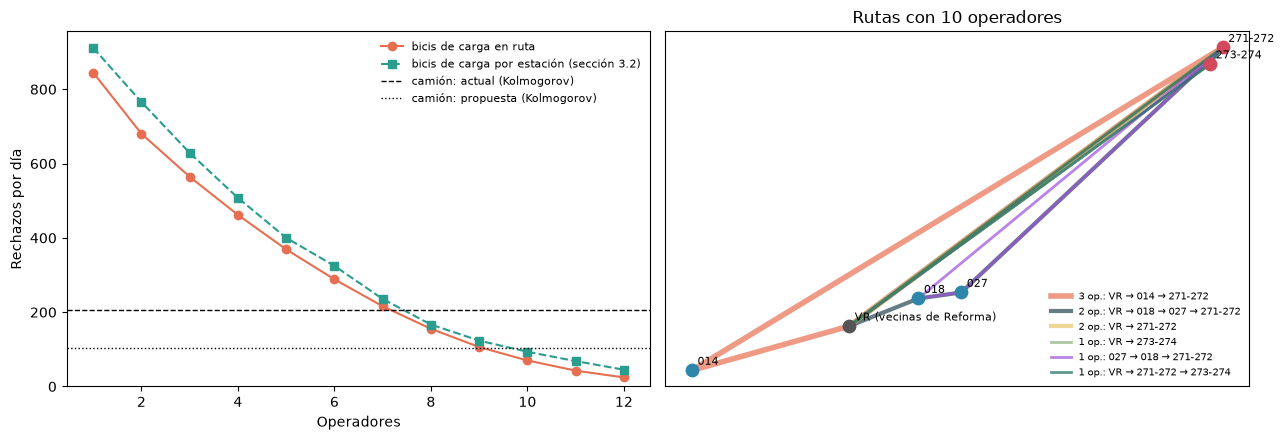

In [18]:
DISENO = {h["operadores"]: h["diseño"] for h in busqueda}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(rutas.index, rutas.rechazos, marker="o", color="#e76f51", label="bicis de carga en ruta")
ax[0].plot(rutas.index, rutas["por estación (sección 3.2)"], marker="s", color="#2a9d8f", ls="--", label="bicis de carga por estación (sección 3.2)")
for nombre, ls in [("actual", "--"), ("propuesta", ":")]:
    ax[0].axhline(cam_cap[nombre], color="black", ls=ls, lw=1, label=f"camión: {nombre} (Kolmogorov)")
ax[0].set_xlabel("Operadores"); ax[0].set_ylabel("Rechazos por día"); ax[0].set_ylim(0, None); ax[0].legend(frameon=False, fontsize=8)

# Mapa esquemático de las rutas de la flota de 10
o_fig = 10
for e in PARADAS:
    lat, lon = info[e]
    color = "#555555" if e == VR else COLORES[SUBRED[e]]
    ax[1].scatter(lon, lat, s=80, color=color, zorder=3); ax[1].annotate(e if e != VR else "VR (vecinas de Reforma)", (lon, lat), fontsize=8, xytext=(4, 4), textcoords="offset points")
for (r, n), c in zip(DISENO[o_fig].items(), ["#e76f51", "#264653", "#e9c46a", "#8ab17d", "#9d4edd", "#1d6b62", "#bc6c25", "#457b9d"]):
    pts = np.array([info[e] for e in r + r[:1]])
    ax[1].plot(pts[:, 1], pts[:, 0], color=c, lw=1 + n, alpha=0.7, label=f"{n} op.: {' → '.join(r)}")
ax[1].set_title(f"Rutas con {o_fig} operadores"); ax[1].legend(frameon=False, fontsize=7, loc="lower right"); ax[1].set_xticks([]); ax[1].set_yticks([])
fig.tight_layout(); fig.savefig(DIR_FIG / "bdb_rutas.png", dpi=150, bbox_inches="tight"); plt.show()

En el mapa se ve la forma de la solución: lanzaderas que salen de la zona de Reforma (VR, 014, 018 y 027) y llegan a Buenavista. La 014 queda lejos (3 km), así que sus rutas son las más largas (47 min por vuelta).

## 7. Combinación de camión y bicis de carga

El camión sigue haciendo lo mismo y se le agregan de 1 a 6 bicis de carga en ruta. Se prueba con dos camiones:
- la **política actual**;
- la **propuesta con camión de 40 bicis**, la versión realista de `camion.ipynb`.

Las reglas de los operadores se recalculan sabiendo lo que hará el camión: sus acciones entran en los tramos de Kolmogorov de la sección 2. Las rutas se buscan igual que en la sección 6.2.

In [19]:
# Camión + bicis de carga. El camión hace lo mismo que antes; las reglas de los operadores se recalculan
# sabiendo lo que hará el camión (el camión entra en los tramos de Kolmogorov). Las rutas se buscan igual que en 6.1.
t0 = time.time()
combo = {}
for cam in ["actual", "propuesta (40)"]:
    combo[cam] = buscar(6, camion=cam)
    combo[cam].insert(0, {"operadores": 0, "rechazos": costo_diseno({}, camion=cam), "diseño": {}})
tabla_combo = pd.DataFrame([{"camión": cam, "operadores": h["operadores"], "rechazos": h["rechazos"], "rutas": describir(h["diseño"])}
                            for cam, hs in combo.items() for h in hs])
tabla_combo.round(1).to_csv(DIR_TABLAS / "bdb_combinacion.csv", index=False)
print(f"({time.time() - t0:.0f} s)")
tabla_combo.pivot(index="operadores", columns="camión", values="rechazos").round(1)

(428 s)


camión,actual,propuesta (40)
operadores,,
0,206.3,192.2
1,90.1,84.6
2,40.4,46.9
3,28.5,35.9
4,22.6,28.0
5,21.6,21.0
6,20.0,16.4


In [20]:
tabla_combo.round(1)

,camión,operadores,rechazos,rutas
0,actual,0,206.3,
1,actual,1,90.1,1 en VR → 014 → 271-272 → 273-274 → 027 → 018 → VR (55 min)
2,actual,2,40.4,1 en VR → 014 → 271-272 → 273-274 → 027 → 018 → VR (55 min); 1 en VR → 271-272 → 273-274 → VR (39 min)
3,actual,3,28.5,1 en VR → 014 → 271-272 → 273-274 → 027 → 018 → VR (55 min); 1 en VR → 271-272 → 273-274 → VR (39 min); 1 en VR → 018 → 027 → 271-272 → VR (42 min)
4,actual,4,22.6,1 en VR → 014 → 271-272 → 273-274 → 027 → 018 → VR (55 min); 1 en VR → 271-272 → 273-274 → VR (39 min); 1 en VR → 273-274 → VR (35 min); 1 en 027 → 018 → 271-272 → 027 (35 min)
5,actual,5,21.6,2 en VR → 014 → 271-272 → 273-274 → 027 → 018 → VR (55 min); 1 en VR → 271-272 → 273-274 → VR (39 min); 1 en VR → 273-274 → VR (35 min); 1 en 027 → 018 → 271-272 → 027 (35 min)
6,actual,6,20.0,2 en VR → 014 → 271-272 → 273-274 → 027 → 018 → VR (55 min); 2 en VR → 273-274 → VR (35 min); 1 en VR → 271-272 → 273-274 → VR (39 min); 1 en 027 → 018 → 271-272 → 027 (35 min)
7,propuesta (40),0,192.2,
8,propuesta (40),1,84.6,1 en 027 → 018 → 271-272 → 273-274 → 027 (37 min)
9,propuesta (40),2,46.9,1 en 014 → 018 → 027 → 273-274 → 271-272 → 014 (53 min); 1 en VR → 018 → 027 → 271-272 → VR (42 min)


**Resultados** (septiembre, sin variación entre días)

| bicis de carga | camión actual | camión de 40 |
|---|---|---|
| 0 | 206 | 192 |
| 1 | 90 | 85 |
| 2 | 40 | 47 |
| 3 | 28 | 36 |
| 4 | 23 | 28 |
| 6 | 20 | 16 |

- **La combinación cambia mucho el resultado.** Con una sola bici de carga, los rechazos del camión actual bajan de 206 a 90. Con dos, a 40: menos que la propuesta con camión (103) y que 10 bicis de carga solas (70).
- Casi todo se gana con las primeras 2 o 3 bicis; de 4 en adelante la mejora es poca.
- El camión y las bicis hacen cosas distintas. El camión mueve los volúmenes grandes de Buenavista. Las bicis cubren lo que el camión deja: los ratos entre sus visitas y las estaciones de Reforma. Por eso, con el camión actual, la primera bici toma la vuelta larga que pasa por las 5 estaciones (VR → 014 → 271-272 → 273-274 → 027 → 018, 55 min).
- Con bicis de carga casi da igual cuál de los dos camiones se use. El camión no tiene que cambiar su plan: basta con agregarle bicis.

## 8. Comparación final en los escenarios de demanda

Todas las alternativas con el mismo simulador, los mismos escenarios y la misma variación entre días que en la sección 4. Las alternativas de las secciones 6 y 7 se simulan con 500 días cada una; el resto viene de la sección 4.

In [21]:
# Escenarios de demanda (como en la sección 4): rutas solas y combinaciones, con variación entre días
N_SIM2 = 500
ALT2 = {f"bicis en ruta ({o} op.)": (DISENO[o], None) for o in [8, 10]}
for cam, etiqueta in [("actual", "camión actual"), ("propuesta (40)", "camión de 40")]:
    for o in [2, 4, 6]:
        ALT2[f"{etiqueta} + {o} bicis en ruta"] = ({h["operadores"]: h["diseño"] for h in combo[cam]}[o], cam)
t0 = time.time()
filas = []
for e_i, (esc, f) in enumerate(F_ESC.items()):
    for a_i, (nombre, (dis, cam)) in enumerate(ALT2.items()):
        s, v = simular_rutas(dis, N_SIM2, f=f, cv=CV, semilla=900 + 10 * e_i + a_i, camion=cam)
        rech, hechos = (s[:, :, 0] + s[:, :, 1]).sum(1), (s[:, :, 2] + s[:, :, 3]).sum(1)
        filas.append({"política": nombre, "escenario": esc, "rechazos (media)": rech.mean(),
                      "IC 95 %": 1.96 * rech.std(ddof=1) / np.sqrt(N_SIM2), "rechazos P95": np.percentile(rech, 95),
                      "% demanda atendida": 100 * hechos.sum() / (hechos.sum() + rech.sum()),
                      "bicis movidas": (s[:, :, 4:8]).sum((1, 2)).mean(),
                      "movidas por bicis de carga": (s[:, :, 4:6]).sum((1, 2)).mean()})
print(f"({time.time() - t0:.0f} s)")
todo2 = pd.concat([todo, pd.DataFrame(filas)], ignore_index=True)
todo2.round(1).to_csv(DIR_TABLAS / "bdb_escenarios_todo.csv", index=False)
ORDEN_ALT2 = ORDEN_ALT + list(ALT2)
todo2.pivot(index="política", columns="escenario", values="rechazos (media)").reindex(index=ORDEN_ALT2, columns=list(F_ESC)).round(1)

(141 s)


escenario,baja,base,alta
política,,,
camión: actual,232.7,270.6,410.9
camión: propuesta,115.3,126.4,187.7
camión: propuesta (40 bicis),201.6,226.2,339.0
bicis de carga (6 operadores),317.3,349.4,502.4
bicis de carga (8 operadores),172.5,199.0,305.9
bicis de carga (10 operadores),104.7,121.4,202.1
bicis de carga (12 operadores),58.3,69.2,131.5
bicis en ruta (8 op.),164.7,187.6,294.5
bicis en ruta (10 op.),92.5,104.4,194.2


**Resultados** (con variación entre días)

| | baja | base | alta |
|---|---|---|---|
| camión actual | 233 | 271 | 411 |
| camión: propuesta (sin límite) | 115 | 126 | 188 |
| bicis de carga por estación, 10 op. | 105 | 121 | 202 |
| bicis en ruta, 8 op. | 165 | 188 | 295 |
| bicis en ruta, 10 op. | 93 | 104 | 194 |
| camión actual + 2 bicis en ruta | 78 | 93 | 179 |
| camión actual + 4 bicis en ruta | 55 | 56 | 117 |
| camión de 40 + 4 bicis en ruta | 51 | 57 | 115 |
| camión de 40 + 6 bicis en ruta | 33 | 41 | 80 |

- **Rutas contra operadores por estación:** con 10 operadores, las rutas bajan los rechazos de 121 a 104 en el escenario base (−14 %).
- **Combinación:** el camión actual con solo 2 bicis en ruta baja los rechazos de 271 a 93 en el escenario base (**−66 %**). Con 4 bicis, a 56 (**−79 %**). Se mantiene en los tres escenarios.
- Las bicis de carga de la combinación mueven pocas bicis: unas 270 a 320 por día. El camión sigue haciendo el grueso, unas 1,000.
- En los días malos también mejora: el P95 del escenario base baja de 454 (camión actual) a 225 con 2 bicis y a 136 con 4.

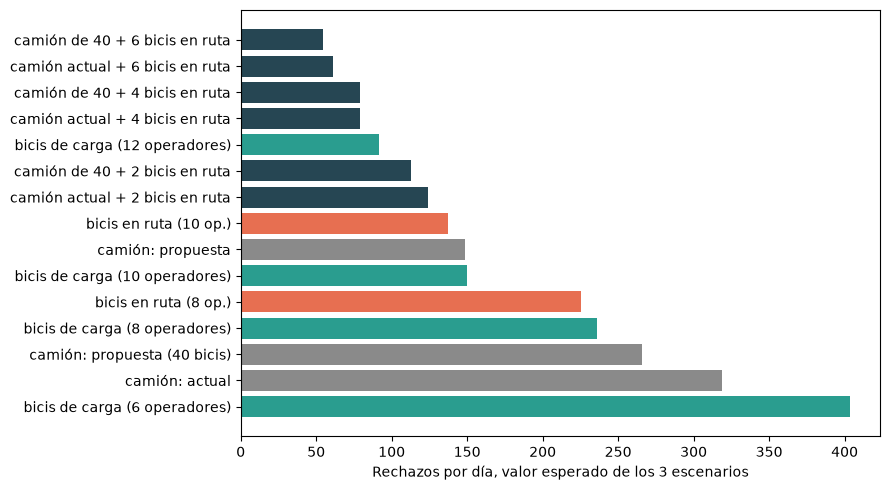

,Valor esperado,Laplace,Wald (peor caso),Hurwicz (α = 0.5),Savage (máx. arrepentimiento)
política,,,,,
camión de 40 + 6 bicis en ruta,54.5,51.2,79.7,56.6,0.0
camión actual + 6 bicis en ruta,61.4,58.5,84.7,63.6,9.1
camión de 40 + 4 bicis en ruta,78.7,74.6,115.4,83.2,35.6
camión actual + 4 bicis en ruta,79.3,76.0,116.6,85.9,36.9
bicis de carga (12 operadores),91.5,86.4,131.5,94.9,51.8
camión de 40 + 2 bicis en ruta,113.1,107.0,162.2,117.8,82.5
camión actual + 2 bicis en ruta,123.9,116.7,179.4,128.5,99.6
bicis en ruta (10 op.),137.1,130.4,194.2,143.3,114.4
camión: propuesta,148.3,143.1,187.7,151.5,108.0


In [22]:
M2 = todo2.pivot(index="política", columns="escenario", values="rechazos (media)").reindex(index=ORDEN_ALT2, columns=list(F_ESC))
arrep2 = M2 - M2.min()
criterios2 = pd.DataFrame({
    "Valor esperado": M2 @ PROB,
    "Laplace": M2.mean(axis=1),
    "Wald (peor caso)": M2.max(axis=1),
    f"Hurwicz (α = {ALFA})": ALFA * M2.min(axis=1) + (1 - ALFA) * M2.max(axis=1),
    "Savage (máx. arrepentimiento)": arrep2.max(axis=1),
})
criterios2.round(1).to_csv(DIR_TABLAS / "bdb_criterios_todo.csv")

fig, ax = plt.subplots(figsize=(9, 5))
ve = criterios2["Valor esperado"].sort_values()
colores = ["#8a8a8a" if a.startswith("camión:") else "#2a9d8f" if a.startswith("bicis de carga") else
           "#e76f51" if a.startswith("bicis en ruta") else "#264653" for a in ve.index]
ax.barh(ve.index, ve.values, color=colores)
ax.invert_yaxis(); ax.set_xlabel("Rechazos por día, valor esperado de los 3 escenarios")
fig.tight_layout(); fig.savefig(DIR_FIG / "bdb_criterios_todo.png", dpi=150, bbox_inches="tight"); plt.show()
criterios2.round(1).sort_values("Valor esperado")

**Resultados**

- Los cinco criterios eligen **camión de 40 + 6 bicis en ruta** (55 rechazos esperados por día), seguido de cerca por camión actual + 6 (61). Otra vez, más recursos siempre ayudan; lo útil es comparar con recursos parecidos.
- Con muy pocos recursos extra, la combinación ya le gana a todo lo que usa un solo medio de transporte. **Camión actual + 2 bicis** (124 en valor esperado) le gana a 10 bicis de carga en ruta sin camión (137) y a la propuesta con un camión sin límite de bicis (148).
- El orden es el mismo con los cinco criterios porque las mejores alternativas ganan en los tres escenarios.

## 9. Conclusión y límites

**¿Hay rutas que optimicen el reabastecimiento solo con bicis de carga?**
- Sí, pero no es una sola ruta. Lo mejor es un conjunto de lanzaderas cortas de la zona de Reforma a Buenavista, con la mayoría de los operadores en la 271-272 y apoyándose en las vecinas de Reforma.
- En ruta se necesitan menos operadores que con operadores fijos por estación: con 10, los rechazos son 104 contra 121 en el escenario base. Aun así, hacen falta 8 operadores para mejorar al camión actual y 10 para igualar la propuesta con camión.

**¿Cambia y mejora la combinación de camión y bicis de carga?**
- Sí, y es la mejor alternativa de todo el proyecto. Con el camión actual y solo **2 bicis de carga en ruta**, los rechazos bajan 66 % en el escenario base (271 → 93). Con 4, bajan 79 % (271 → 56).
- Es mejor que 10 bicis de carga solas y mejor que la propuesta con camión sin límite, con muchos menos recursos extra.
- No hace falta cambiar el plan del camión: el camión mueve volumen, y las bicis cubren los huecos entre sus visitas y las estaciones de Reforma.

**Límites**
- **Operadores.** Cada uno trabaja de 5:00 a 24:00 (unos 2 turnos). Falta comparar costos.
- **Vecinas de Reforma (VR).** Se toman como una sola parada en su centro. Se supone que en la mañana siempre tienen bicis para dar y en la tarde lugares para recibir; los datos dicen que les sobran o faltan cientos por hora, así que es razonable, pero no está comprobado estación por estación.
- **Búsqueda de rutas.** Es voraz con mejora local y evalúa con 40 días simulados, así que puede haber diseños un poco mejores. La regla de cada parada ve solo un paso adelante.
- **Camión.** En la combinación el camión no cambia su plan. Si se optimizaran juntos, podría mejorar todavía más.
- **Lo demás.** Siguen los supuestos de las etapas anteriores: tasas de septiembre escaladas por escenario, usuario rechazado se pierde y arranque óptimo a las 5:00.